# 07 · Comparative Analytics: mobilitas (Zenodo) vs penduduk (BPS)

**Anggota 7:** Zahira Anindya Putri - 24/543202/TK/60347

**Pertanyaan:** seberapa baik data device mewakili sebaran penduduk antar kapanewon, dan kapanewon mana yang over/under-represented?

**Aturan data (dari catatan tim):**
- Join selalu pakai `kapanewon_code` (JETIS ada di Bantul dan Kota Yogyakarta).
- `n_users` / `ratio`: satu angka per kapanewon untuk seluruh periode (Des 2021-Apr 2022). Tidak dibagi per tahun, tidak dijumlahkan.
- `mean_n_maids_malam` (jam 22-05) berbeda per tahun, tapi **tidak sebanding antar tahun** (supply device berubah 1 Jan dan 16 Feb 2022; 2021 hanya Desember). Bandingkan hanya dalam tahun yang sama, atau pakai peringkat / `mean_share_in_hour`.
- Slot kosong = disensor (<5 device), bukan nol.

## 1. Setup dan load data

In [1]:
from pathlib import Path
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUT = ROOT / "outputs" / "comparative"; OUT.mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(ROOT / "data/integrated/jogjapulse.duckdb"), read_only=True)
k = con.sql("SELECT * FROM integrated_kapanewon").df()
r = con.sql("SELECT * FROM integrated_kapanewon_regime").df()
hm = pd.read_parquet(ROOT / "data/clean/home_maids_vs_population_kapanewon.parquet")

def label(df):
    return df["kapanewon"].str.title() + " (" + df["kab_kota"].str.title() + ")"
k["label"], r["label"], hm["label"] = label(k), label(r), label(hm)

print(k.groupby("tahun").size().to_dict(), "| hm:", hm.shape)
k[["pop_bps", "n_users", "mean_n_maids_malam", "maids_per_1000_penduduk", "ratio"]].describe().T.round(2)

{2021: 78, 2022: 78} | hm: (78, 9)


,count,mean,std,min,25%,50%,75%,max
pop_bps,156.0,47489.13,25284.45,10549.00,31075.75,38020.50,55774.50,133500.00
n_users,156.0,6556.65,8142.36,256.00,1297.00,3337.00,7403.00,39609.00
mean_n_maids_malam,156.0,48.44,62.03,6.26,12.04,26.37,54.72,361.02
maids_per_1000_penduduk,156.0,1.52,1.53,0.20,0.57,1.00,1.86,10.11
ratio,156.0,0.14,0.26,0.01,0.04,0.09,0.15,2.25


## 2. Validasi definisi kolom dan penyebut penduduk
`ratio = n_users / pop_actual` (device berumah per 1 penduduk, bukan per 1000). `pop_actual` (Zenodo) dan `pop_bps` (tim) tidak identik, cek perbedaannya.

In [2]:
assert np.allclose(hm["ratio"], hm["n_users"] / hm["pop_actual"])
assert ((hm["ratio"] > 1) == hm["ratio_gt_1"]).all()
print("Kapanewon dengan device > penduduk:\n", hm.loc[hm["ratio"] > 1, ["label", "n_users", "pop_actual", "ratio"]])

c = hm.merge(k.loc[k.tahun == 2022, ["kapanewon_code", "pop_bps"]], on="kapanewon_code")
c["selisih_pct"] = (c["pop_actual"] / c["pop_bps"] - 1) * 100
print(c.groupby("kab_kota")["selisih_pct"].agg(["mean", "min", "max"]).round(1))

Kapanewon dengan device > penduduk:
                       label  n_users  pop_actual     ratio
73  Gondomanan (Yogyakarta)    28874     12850.0  2.247004
             mean   min  max
kab_kota                    
BANTUL        1.5  -2.8  8.8
GUNUNGKIDUL  -0.1  -0.6  0.6
KULON PROGO  -0.5  -0.9 -0.4
SLEMAN       -0.8  -2.1 -0.2
YOGYAKARTA  -10.5 -16.2 -3.5


## 3. Korelasi: device vs penduduk
- **A.** `n_users` (device berumah, seluruh periode) vs `pop_actual`, n = 78.
- **B.** `mean_n_maids_malam` vs `pop_bps`, per tahun.

Tiap analisis dihitung dengan dan tanpa Gondomanan (outlier yang disebut README).

In [3]:
def corr_row(d, x, y, name):
    d = d[(d[x] > 0) & (d[y] > 0)].dropna(subset=[x, y])
    return dict(analisis=name, n=len(d),
                pearson_linear=pearsonr(d[x], d[y])[0],
                pearson_loglog=pearsonr(np.log10(d[x]), np.log10(d[y]))[0],
                spearman=spearmanr(d[x], d[y])[0])

nog = lambda d: d[d.kapanewon != "GONDOMANAN"]
rows = [corr_row(hm, "pop_actual", "n_users", "A. n_users vs pop_actual (semua)"),
        corr_row(nog(hm), "pop_actual", "n_users", "A. n_users vs pop_actual (tanpa Gondomanan)")]
for y, g in k.groupby("tahun"):
    rows += [corr_row(g, "pop_bps", "mean_n_maids_malam", f"B. malam vs pop_bps {y} (semua)"),
             corr_row(nog(g), "pop_bps", "mean_n_maids_malam", f"B. malam vs pop_bps {y} (tanpa Gondomanan)")]

# Uji ketahanan: analisis A diulang dengan penyebut pop_bps
t = hm.merge(k.loc[k.tahun == 2022, ["kapanewon_code", "pop_bps"]], on="kapanewon_code")
rows += [corr_row(t, "pop_bps", "n_users", "A'. n_users vs pop_bps (semua)"),
         corr_row(nog(t), "pop_bps", "n_users", "A'. n_users vs pop_bps (tanpa Gondomanan)")]

corr = pd.DataFrame(rows).round(3)
corr.to_csv(OUT / "korelasi.csv", index=False)
corr

,analisis,n,pearson_linear,pearson_loglog,spearman
0,A. n_users vs pop_actual (semua),78,0.723,0.600,0.614
1,A. n_users vs pop_actual (tanpa Gondomanan),77,0.820,0.688,0.672
2,B. malam vs pop_bps 2021 (semua),78,0.796,0.681,0.672
3,B. malam vs pop_bps 2021 (tanpa Gondomanan),77,0.812,0.732,0.711
4,B. malam vs pop_bps 2022 (semua),78,0.746,0.631,0.621
5,B. malam vs pop_bps 2022 (tanpa Gondomanan),77,0.850,0.732,0.682
6,A'. n_users vs pop_bps (semua),78,0.737,0.629,0.632
7,A'. n_users vs pop_bps (tanpa Gondomanan),77,0.834,0.713,0.691


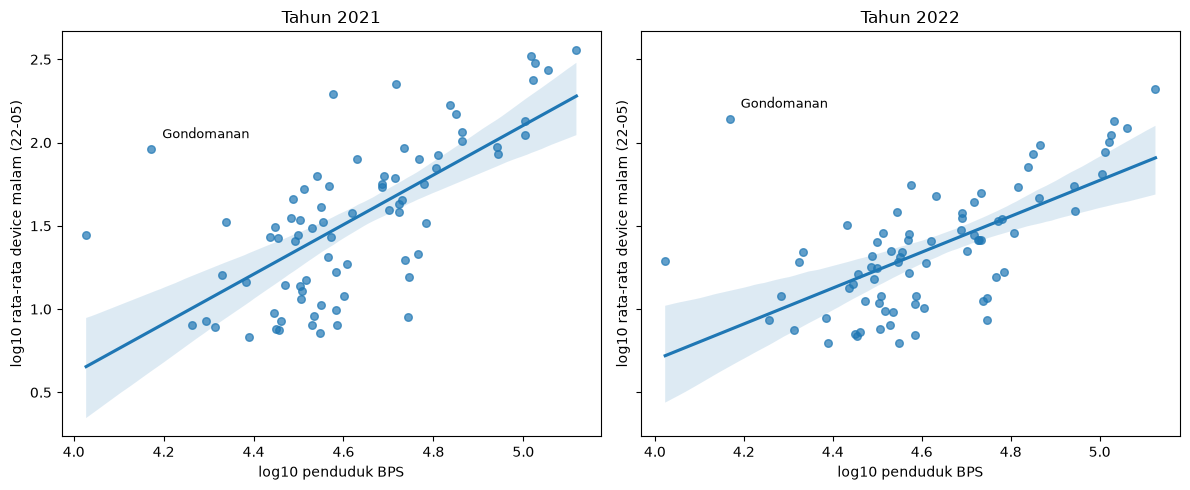

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (y, g) in zip(axes, k.groupby("tahun")):
    d = g.dropna(subset=["mean_n_maids_malam"])
    sns.regplot(x=np.log10(d.pop_bps), y=np.log10(d.mean_n_maids_malam), ax=ax,
                scatter_kws=dict(s=30, alpha=.7))
    gm = d[d.kapanewon == "GONDOMANAN"]
    ax.annotate("Gondomanan", (np.log10(gm.pop_bps.iloc[0]), np.log10(gm.mean_n_maids_malam.iloc[0])),
                xytext=(8, 8), textcoords="offset points", fontsize=9)
    ax.set(title=f"Tahun {y}", xlabel="log10 penduduk BPS", ylabel="log10 rata-rata device malam (22-05)")
plt.tight_layout(); plt.savefig(OUT / "scatter_penduduk_vs_device.png", dpi=200); plt.show()

## 4. Over / under-represented
Residual regresi log-log (`mean_n_maids_malam` ~ `pop_bps`), dihitung **per tahun**. Z positif = device malam lebih banyak dari yang diharapkan dari jumlah penduduk.
Karena Gondomanan menarik garis regresi, ada versi yang di-fit tanpa Gondomanan sebagai pembanding.

In [5]:
def resid_z(g, dev="mean_n_maids_malam", exclude=("GONDOMANAN",), fit_excluding=False):
    g = g.dropna(subset=[dev]).copy()
    g = g[(g.pop_bps > 0) & (g[dev] > 0)]
    X, yv = sm.add_constant(np.log10(g.pop_bps)), np.log10(g[dev])
    fit_mask = ~g.kapanewon.isin(exclude) if fit_excluding else np.ones(len(g), bool)
    m = sm.OLS(yv[fit_mask], X[fit_mask]).fit()
    res = yv - m.predict(X)
    g["resid_z"] = (res - res[fit_mask].mean()) / res[fit_mask].std()
    g["r2"] = m.rsquared
    return g

kz = pd.concat([resid_z(g) for _, g in k.groupby("tahun")])
kz_ex = pd.concat([resid_z(g, fit_excluding=True) for _, g in k.groupby("tahun")])
print("R2 (semua):", kz.groupby("tahun")["r2"].first().round(2).to_dict(),
      "| R2 (fit tanpa Gondomanan):", kz_ex.groupby("tahun")["r2"].first().round(2).to_dict())

cols = ["label", "pop_bps", "mean_n_maids_malam", "resid_z"]
for y in sorted(kz.tahun.unique()):
    g = kz[kz.tahun == y]
    print(f"\n=== {y}: OVER ===");  display(g.nlargest(10, "resid_z")[cols].round(2))
    print(f"=== {y}: UNDER ===");   display(g.nsmallest(10, "resid_z")[cols].round(2))

# Kapanewon yang over/under di KEDUA tahun = temuan yang lebih bisa dipercaya
piv = kz.pivot(index="label", columns="tahun", values="resid_z")
print("\nKonsisten over (z>1 di 2021 dan 2022):", piv[(piv > 1).all(axis=1)].round(2).to_dict("index"))
print("Konsisten under (z<-1 di keduanya):", sorted(piv[(piv < -1).all(axis=1)].index))
kz.to_csv(OUT / "residual_z.csv", index=False)

R2 (semua): {2021: 0.46, 2022: 0.4} | R2 (fit tanpa Gondomanan): {2021: 0.54, 2022: 0.54}

=== 2021: OVER ===


,label,pop_bps,mean_n_maids_malam,resid_z
146,Gondomanan (Yogyakarta),14869,91.14,3.18
124,Pakem (Sleman),37656,196.47,2.40
148,Pakualaman (Yogyakarta),10657,28.00,2.32
102,Seyegan (Sleman),51967,225.84,1.97
144,Kraton (Yogyakarta),21761,33.40,1.19
94,Gamping (Sleman),104020,330.48,1.14
154,Kotagede (Yogyakarta),34708,63.03,1.11
114,Ngemplak (Sleman),68576,167.35,1.06
132,Gondokusuman (Yogyakarta),42639,79.58,1.02
100,Minggir (Sleman),32459,52.83,1.02


=== 2021: UNDER ===


,label,pop_bps,mean_n_maids_malam,resid_z
80,Semin (Gunungkidul),55521,9.01,-2.24
86,Saptosari (Gunungkidul),38419,8.05,-1.69
70,Tepus (Gunungkidul),35300,7.17,-1.68
74,Karangmojo (Gunungkidul),55645,15.68,-1.54
82,Ngawen (Gunungkidul),33855,7.99,-1.46
4,Panjatan (Kulon Progo),38385,9.91,-1.42
64,Patuk (Gunungkidul),34264,9.11,-1.32
44,Dlingo (Bantul),40002,11.91,-1.27
72,Semanu (Gunungkidul),58330,21.35,-1.24
78,Rongkop (Gunungkidul),28543,7.45,-1.23



=== 2022: OVER ===


,label,pop_bps,mean_n_maids_malam,resid_z
147,Gondomanan (Yogyakarta),14725,138.89,4.43
149,Pakualaman (Yogyakarta),10549,19.52,1.99
125,Pakem (Sleman),37644,55.84,1.51
107,Depok (Sleman),133500,209.49,1.44
119,Sleman (Sleman),73388,97.09,1.25
131,Jetis (Yogyakarta),26976,32.20,1.22
117,Ngaglik (Sleman),107892,133.91,1.11
153,Umbulharjo (Yogyakarta),70937,85.07,1.11
133,Gondokusuman (Yogyakarta),42752,47.86,1.06
155,Kotagede (Yogyakarta),35071,38.29,1.05


=== 2022: UNDER ===


,label,pop_bps,mean_n_maids_malam,resid_z
81,Semin (Gunungkidul),55734,8.59,-1.98
71,Tepus (Gunungkidul),35365,6.29,-1.70
87,Saptosari (Gunungkidul),38533,7.03,-1.68
77,Ponjong (Gunungkidul),54553,11.20,-1.54
75,Karangmojo (Gunungkidul),55896,11.64,-1.52
67,Paliyan (Gunungkidul),32095,7.60,-1.26
83,Ngawen (Gunungkidul),33817,8.06,-1.26
79,Rongkop (Gunungkidul),28488,6.91,-1.21
45,Dlingo (Bantul),40257,10.12,-1.19
91,Tanjungsari (Gunungkidul),28225,7.05,-1.16



Konsisten over (z>1 di 2021 dan 2022): {'Gondokusuman (Yogyakarta)': {2021: 1.02, 2022: 1.06}, 'Gondomanan (Yogyakarta)': {2021: 3.18, 2022: 4.43}, 'Kotagede (Yogyakarta)': {2021: 1.11, 2022: 1.05}, 'Kraton (Yogyakarta)': {2021: 1.19, 2022: 1.02}, 'Pakem (Sleman)': {2021: 2.4, 2022: 1.51}, 'Pakualaman (Yogyakarta)': {2021: 2.32, 2022: 1.99}}
Konsisten under (z<-1 di keduanya): ['Dlingo (Bantul)', 'Girisubo (Gunungkidul)', 'Karangmojo (Gunungkidul)', 'Ngawen (Gunungkidul)', 'Panggang (Gunungkidul)', 'Patuk (Gunungkidul)', 'Ponjong (Gunungkidul)', 'Rongkop (Gunungkidul)', 'Saptosari (Gunungkidul)', 'Semanu (Gunungkidul)', 'Semin (Gunungkidul)', 'Tanjungsari (Gunungkidul)', 'Tepus (Gunungkidul)']


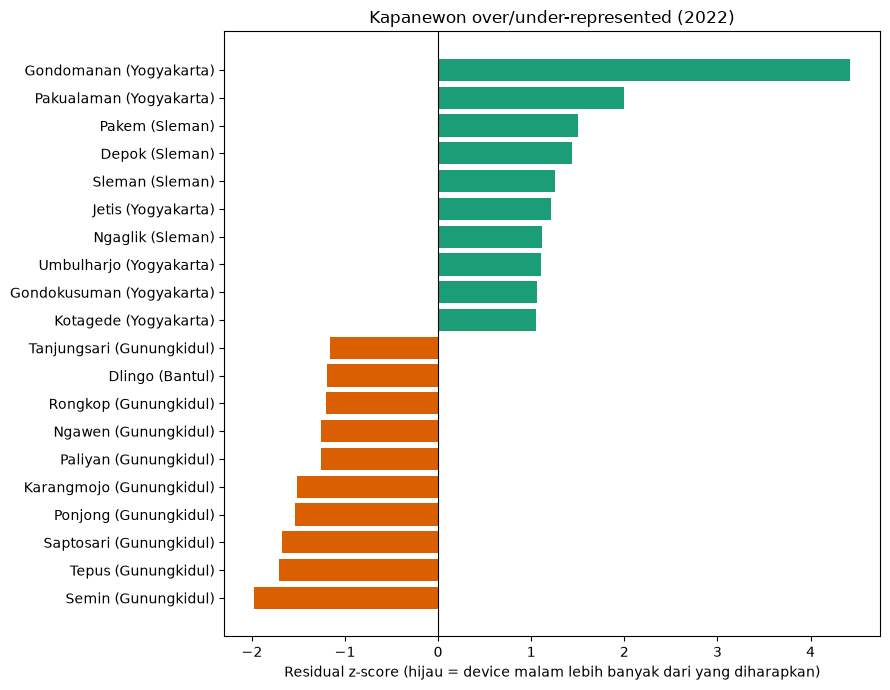

In [6]:
g = kz[kz.tahun == kz.tahun.max()].sort_values("resid_z")
top = pd.concat([g.head(10), g.tail(10)])
plt.figure(figsize=(9, 7))
plt.barh(top["label"], top["resid_z"], color=["#d95f02" if v < 0 else "#1b9e77" for v in top["resid_z"]])
plt.axvline(0, c="k", lw=.8)
plt.title(f"Kapanewon over/under-represented ({kz.tahun.max()})")
plt.xlabel("Residual z-score (hijau = device malam lebih banyak dari yang diharapkan)")
plt.tight_layout(); plt.savefig(OUT / "bar_over_under.png", dpi=200); plt.show()

## 5. Cakupan device per penduduk (`ratio`)
Ukuran utama representasi: device berumah per penduduk. Skala log supaya kapanewon Gunungkidul (0,01-0,02) tetap terlihat. Garis merah = 1 device per penduduk.

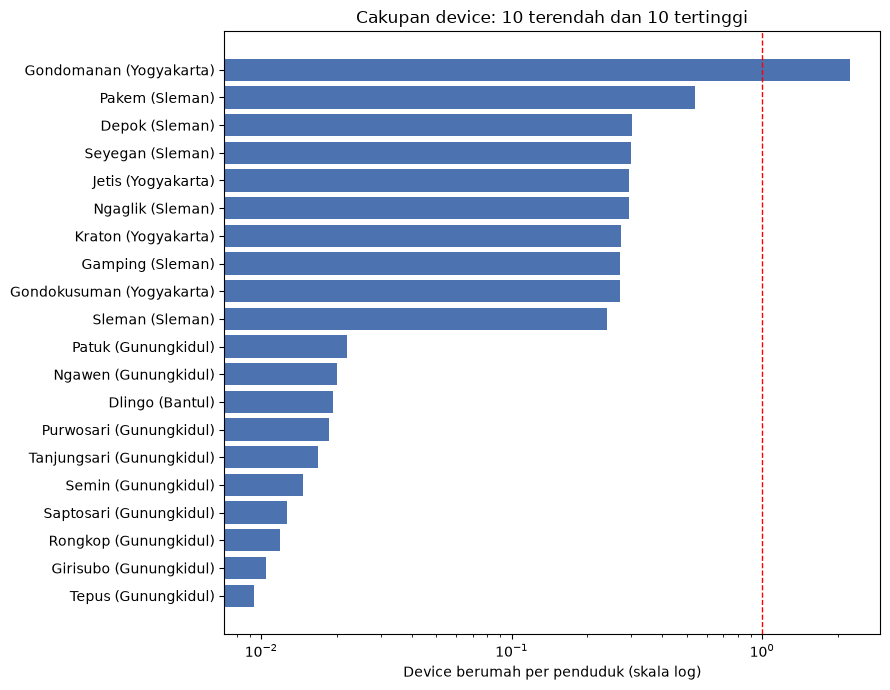

kab_kota
BANTUL         0.103
GUNUNGKIDUL    0.022
KULON PROGO    0.075
SLEMAN         0.163
YOGYAKARTA     0.145
Name: ratio, dtype: float64


In [7]:
g = hm.sort_values("ratio")
top = pd.concat([g.head(10), g.tail(10)])
plt.figure(figsize=(9, 7))
plt.barh(top["label"], top["ratio"], color="#4c72b0")
plt.xscale("log"); plt.axvline(1, c="red", ls="--", lw=1)
plt.xlabel("Device berumah per penduduk (skala log)")
plt.title("Cakupan device: 10 terendah dan 10 tertinggi")
plt.tight_layout(); plt.savefig(OUT / "bar_ratio_n_users.png", dpi=200); plt.show()

print(hm.groupby("kab_kota")["ratio"].median().round(3))

## 6. Stabilitas peringkat antar waktu
Pakai peringkat dan `mean_share_in_hour`, bukan jumlah device mentah.

supply_regime      A      B      C
supply_regime                     
A              1.000  0.959  0.829
B              0.959  1.000  0.857
C              0.829  0.857  1.000
Spearman peringkat rasio 2021 vs 2022: 0.901


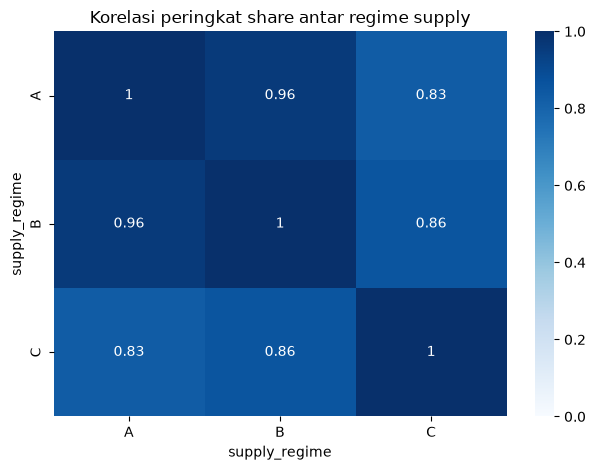

In [8]:
w = r.pivot(index="kapanewon_code", columns="supply_regime", values="mean_share_in_hour")
rho_regime = w.corr(method="spearman").round(3)
print(rho_regime)

yr = k.pivot(index="kapanewon_code", columns="tahun", values="maids_per_1000_penduduk")
rho_year = yr.corr(method="spearman").iloc[0, 1]
print("Spearman peringkat rasio 2021 vs 2022:", round(rho_year, 3))

sns.heatmap(rho_regime, annot=True, cmap="Blues", vmin=0, vmax=1)
plt.title("Korelasi peringkat share antar regime supply")
plt.tight_layout(); plt.savefig(OUT / "rank_stability_regime.png", dpi=200); plt.show()

## 7. Insights
1. Device berumah berkorelasi positif dengan penduduk: Pearson 0,82 tanpa Gondomanan (n = 77) dan 0,72 jika Gondomanan ikut; Spearman 0,61-0,67. Hasil hampir sama dengan penyebut `pop_bps` (0,83), jadi kesimpulan tidak bergantung pada pilihan sumber penduduk. Hubungannya sedang sampai kuat, bukan sempurna.
2. Gondomanan satu-satunya kapanewon dengan device > penduduk (28.874 vs 12.850; rasio 2,25) dan z-residual malam tertinggi di kedua tahun (3,2 dan 4,4). Konsisten dengan perannya sebagai pusat kota dan wisata.
3. Over-represented yang konsisten di 2021 dan 2022 (z > 1) hampir semuanya Kota Yogyakarta. Yang jelas: Gondomanan dan Pakualaman; cukup kuat: Pakem (Sleman). Tipis atau borderline (z sekitar 1,0-1,2): Kraton, Kotagede, Gondokusuman. Under-represented yang konsisten (z < -1) ada 13 kapanewon: 12 di Gunungkidul ditambah Dlingo (Bantul).
4. Cakupan device timpang antar kabupaten (median device berumah per penduduk): Sleman 0,16, Kota Yogyakarta 0,15, Bantul 0,10, Kulon Progo 0,08, Gunungkidul 0,02. Ini soal cakupan data, bukan jumlah orang.
5. Pola relatif stabil: peringkat share antar regime supply rho 0,83-0,96; peringkat rasio 2021 vs 2022 rho 0,90.
6. Ramai secara absolut tidak sama dengan ramai relatif terhadap penduduk. Analisis spasial menempatkan Depok, Ngaglik, Banguntapan, Gamping, dan Kasihan sebagai yang teraktif, tetapi itu kapanewon berpenduduk besar. Setelah dinormalisasi, Banguntapan dan Kasihan tidak lagi menonjol, sedangkan Depok dan Ngaglik tetap sedikit di atas harapan di 2022 (z 1,44 dan 1,11) tetapi tidak di 2021. Yang konsisten di kedua tahun adalah pusat kota (Gondomanan, Pakualaman). Analisis OD juga menunjuk Kota Yogyakarta sebagai pusat kunjungan, dan pola jam membedakan pusat kegiatan (puncak siang) dari permukiman (puncak sore). Ketiganya mengukur hal berbeda, jadi dibaca sebagai gambaran yang saling melengkapi, bukan bukti satu sama lain. OD Mar-Apr 2022 berkualitas rendah.

## 8. Keterbatasan
- Data iklan/SDK: hanya pengguna smartphone dengan aplikasi tertentu; device bukan orang.
- Penduduk menjelaskan hanya sebagian variasi device malam (R² 0,40-0,46; 0,54 jika regresi di-fit tanpa Gondomanan).
- Sensor k = 5: slot <5 device hilang (bukan nol). Di kapanewon pedesaan sangat sedikit slot malam terbit, nilai rata-ratanya tidak stabil dan mungkin bias ke atas, jadi under-representation di Gunungkidul bisa lebih besar dari yang terlihat.
- Jumlah device berubah (1 Jan dan 16 Feb 2022). "2021" hanya Desember (regime A), sedangkan "2022" gabungan regime B dan C, jadi perbandingan antar tahun hanya lewat peringkat atau share.
- `pop_actual` (Zenodo) dan `pop_bps` (tim) berbeda: Kota Yogyakarta rata-rata -10,5%, Bantul utara +5% sampai +9%. BPS dikumpulkan dari sumber berbeda per kabupaten.
- Tujuh baris BPS (semua di Kota Yogyakarta) punya selisih kecil (maks 2,6%) antara total yang dihitung dan total yang tertulis; dampaknya terhadap analisis diabaikan.
- Definisi malam tim 22-05; README memakai 00-05.
- Hubungan korelasional; kampus, wisata, dan komuter adalah hipotesis penjelas, bukan hasil uji.
